# Comparative Analysis: Trial Length & Flexibility Across Experimental Setups

This notebook extracts, processes, and plots training dynamics across multiple experimental setups from **Weights & Biases (W&B)**:
1. **Multi-Project & Multi-Modulation Setups**:
   - **Baseline (No Context)**: Project `ymaze_nocontext` (5 seeds with `r.sca_0.1_l.rat_0.0002`).
   - **DG Modulations ("DG")**: Project `ENC_DECymaze_new_instr` with `D.c.mod`:
     - `sigmoid` (`D.c.mod_sigmoid`)
     - `multiply` (`D.c.mod_multiply`)
     - `concat` (`D.c.mod_concat`)
   - **Decoder Modulations ("Decoder")**: Project `ENC_DECymaze_new_instr` with `D.c.mod`:
     - `enter` (`D.c.mod_enter`)
     - `FiLM` (matches either `D.c.mod_FiLM` OR `afterMLP_FiLM`)
2. **Metrics Handled**:
   - **Trial Length (per step)**:
     - Extracted from `len/len` (Sample Factory episode length in global steps / simulator frames).
     - Each episode consists of **75 trials** with an environment **frameskip of 8**.
     - **Agent decision steps per trial**: $\text{Trial Length} = \frac{\text{len/len}}{75 \times \text{frame\_skip}} = \frac{\text{len/len}}{600}$.
     - *(Optional simulator frames per trial: $\frac{\text{len/len}}{75}$).*
   - **Flexibility Parameter**:
     - Extracted from `custom/flexibility`.
3. **Hierarchical Aggregation**:
   - **Level 1 (Within each seed run)**: Average across its 4 policies ($p \in \{0, 1, 2, 3\}$) to obtain the policy-averaged trajectory for that seed.
   - **Level 2 (Across seeds)**:
     - **Average of Policies**: Overall central curve $\mu(t) = \frac{1}{N} \sum_{s=1}^N \text{policy\_avg}_s(t)$.
     - **Variance Across Seeds**: Unbiased sample variance across seeds:
       $$\operatorname{Var}_{\text{seeds}}(t) = \frac{1}{N - 1} \sum_{s=1}^N \left(\text{policy\_avg}_s(t) - \mu(t)\right)^2$$
4. **Publication Standards**: Formatting strictly follows `figure_making_functions.ipynb` (vector fonts type 42, physical sizing, despined axes, framed-less outside legends, transparent background).


In [179]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import wandb

# ------------------------------------------------------------------------------
# PUBLICATION-STANDARD PLOTTING SETTINGS (from figure_making_functions.ipynb)
# ------------------------------------------------------------------------------
# Ensure text objects are recognized as editable text in final vector plots (not paths)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# Font & sizing: Physical dimensions (standard publication font size is 9)
mpl.rcParams['font.size'] = 9
mpl.rcParams['lines.linewidth'] = 1.2
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# Clean background & tight margins
mpl.rcParams['savefig.transparent'] = True  # Removes unnecessary white background
mpl.rcParams['savefig.bbox'] = 'tight'      # Includes outside legends and removes extra whitespace

# Custom distinct palette (never use default matplotlib cycle)
# Color scheme visually grouping Baseline vs DG modulations vs Decoder modulations
SETUP_COLORS = {
    "No-Context": "#333333",       # Dark gray / black for baseline
    "DG: Sigmoid": "#1f77b4",      # Blue
    "DG: Multiply": "#2ca02c",     # Green
    "DG: Concat": "#17becf",       # Cyan
    "Decoder: Enter": "#ff7f0e",   # Orange
    "Decoder: FiLM": "#d62728",    # Red
}

FALLBACK_COLORS = ["#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22"]

def style_axes_and_legend(ax, legend_loc='upper left', bbox_to_anchor=(1.02, 1)):
    """
    Applies publication standards from figure_making_functions.ipynb:
    - Removes top and right spines ('nobody likes boxes')
    - Removes legend frame and places it outside ('nobody likes frames around legends either')
    """
    ax.axes.spines[['top', 'right']].set_visible(False)
    legend = ax.get_legend()
    if legend:
        legend.set_frame_on(False)
        legend.set_bbox_to_anchor(bbox_to_anchor)
        legend.set_loc(legend_loc)


## 1. Experimental Setups Configuration

Defines W&B project sources and run matching filters for:
- **Baseline**: `ymaze_nocontext`
- **DG Context Modulations**: `ENC_DECymaze_new_instr` (`sigmoid`, `multiply`, `concat`)
- **Decoder Context Modulations**: `ENC_DECymaze_new_instr` (`enter`, `FiLM` via `D.c.mod_FiLM` or `afterMLP_FiLM`)


In [183]:
# Default W&B Entity (Team / Username)
WANDB_ENTITY = "xiaoxionglin-bernstein-center-freiburg"

# Project names
PROJECT_NOCONTEXT = "ymaze_nocontext"
PROJECT_ORACLE = "ENC_DECymaze_norew_instr"
#PROJECT_ORACLE = "NEWymaze_norew_instr"

FILM_PATTERNS = ["D.c.mod_film", "afterMLP_FiLM", "FiLM"]

# ==============================================================================
# EXPERIMENTAL SETUPS ACROSS DIFFERENT W&B PROJECTS
# Each entry defines:
#   - 'project': W&B project name
#   - 'run_names': List of exact run names or run prefixes
#   - 'include_any': Match if ANY of these strings appear in run name or config
#   - 'include_all': Match only if ALL of these strings appear (e.g. learning rate)
# ==============================================================================
EXPERIMENTAL_SETUPS = {
    # --------------------------------------------------------------------------
    # BASELINE: No-Context (from project ymaze_nocontext)
    # --------------------------------------------------------------------------
    "No-Context": {
        "project": PROJECT_NOCONTEXT,
        "entity": WANDB_ENTITY,
        "run_names": [
            "03_noINSTR_see_1111_r.sca_0.1_l.rat_2e-05",
            "12_noINSTR_see_2222_r.sca_0.1_l.rat_2e-05",
            "21_noINSTR_see_3333_r.sca_0.1_l.rat_2e-05",
            "30_noINSTR_see_4444_r.sca_0.1_l.rat_2e-05",
            "39_noINSTR_see_5555_r.sca_0.1_l.rat_2e-05",
        ],
        "include_any": [],
        "include_all": [],
    },


    # --------------------------------------------------------------------------
    # 2. ENCODER-ONLY ("DG") MODULATIONS (from ENC_DECymaze_new_instr)
    # --------------------------------------------------------------------------
    "DG: Sigmoid": {
        "project": PROJECT_ORACLE,
        "include_all": ["sigmoid", "encoderonly"],
        "exclude": ["ablation"],
    },
    "DG: Multiply": {
        "project": PROJECT_ORACLE,
        "include_all": ["newmod", "encoderonly"],
        "exclude": ["ablation"],
    },
    "DG: Concat": {
        "project": PROJECT_ORACLE,
        "include_all": ["encoderonly", "concat"],
        "exclude": ["ablation", "decoderonly"],
    },
    # --------------------------------------------------------------------------
    # 3. DECODER-ONLY MODULATIONS (from ENC_DECymaze_new_instr)
    # --------------------------------------------------------------------------
    "Decoder: Enter": {
        "project": PROJECT_ORACLE,
       "include_all": ["decoderonly", "enter"],
        "exclude": ["ablation"],
    },
    "Decoder: FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["decoderonly"],
        # Handles both D.c.mod_FiLM and afterMLP_FiLM naming systems
       "include_any": ["D.c.mod_film", "afterMLP_FiLM", "FiLM"],
        "exclude": ["ablation"],
    },
    # --------------------------------------------------------------------------
    # 4. ABLATION PAIRS: 3 DG (Sigmoid, Multiply, Concat) x 2 Decoder (Enter, FiLM)
    # --------------------------------------------------------------------------
    ## add to the dictionary for ENC_DEC
    # Pair 1: Sigmoid + Enter
    "Ablation: Sigmoid + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "sigmoid", "enter"],
    },
    # Pair 2: Sigmoid + FiLM
    "Ablation: Sigmoid + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "sigmoid"],
        "include_any": FILM_PATTERNS,
    },
    # Pair 3: Multiply + Enter
    "Ablation: Multiply + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "multiply", "enter"],
    },
    # Pair 4: Multiply + FiLM
    "Ablation: Multiply + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "multiply"],
        "include_any": FILM_PATTERNS,
    },
    # Pair 5: Concat + Enter (e.g. 00_stage0_INSTR_ablation_..._D.c.mod_concat_D.c.mod_enter_...)
    "Ablation: Concat + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "concat", "enter"],
    },
    # Pair 6: Concat + FiLM
    "Ablation: Concat + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "concat"],
        "include_any": FILM_PATTERNS,
    },
}

# ==============================================================================
# ENVIRONMENT & RESAMPLING PARAMETERS
# ==============================================================================
NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75    # 75 trials per episode
FRAME_SKIP = 8             # 8 frame_skip

# Set True for agent decision steps: len / (75 * 8)
# Set False for simulator frames: len / 75
PER_AGENT_STEP = True      

NUM_RESAMPLE_POINTS = 500  # Number of points along interpolated step grid
MAX_STEP = 200e6            # Horizon to plot (e.g. 50M steps). Set None to auto-detect max step

# Local cache file so you don't have to re-fetch from W&B when adjusting plots
CACHE_FILE = "cached_experiments_data.pkl"
FORCE_REFETCH = True       # Set to False to reload from local CACHE_FILE


In [ ]:
## add to the dictionary for ENC_DEC
    # Pair 1: Sigmoid + Enter
    "Ablation: Sigmoid + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "sigmoid", "enter"],
    },
    # Pair 2: Sigmoid + FiLM
    "Ablation: Sigmoid + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "sigmoid"],
        "include_any": FILM_PATTERNS,
    },
    # Pair 3: Multiply + Enter
    "Ablation: Multiply + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "multiply", "enter"],
    },
    # Pair 4: Multiply + FiLM
    "Ablation: Multiply + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "multiply"],
        "include_any": FILM_PATTERNS,
    },
    # Pair 5: Concat + Enter (e.g. 00_stage0_INSTR_ablation_..._D.c.mod_concat_D.c.mod_enter_...)
    "Ablation: Concat + Enter": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "concat", "enter"],
    },
    # Pair 6: Concat + FiLM
    "Ablation: Concat + FiLM": {
        "project": PROJECT_ORACLE,
        "include_all": ["ablation", "concat"],
        "include_any": FILM_PATTERNS,
    },

## 2. Processing & Resampling Helpers

Functions to deduplicate step logs, interpolate onto a common step axis, and average across policies within each seed.


In [175]:
# ==============================================================================
# SECTION 2: PER-POLICY INDEPENDENT EXTRACTION HELPER
# ==============================================================================
def resample_series(df, step_col, metric_col, target_steps):
    """Clean, sort, deduplicate and interpolate onto target_steps; mask out extrapolation."""
    clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
    clean = clean.drop_duplicates(subset=step_col, keep="last")
    if len(clean) < 2 or clean[step_col].nunique() < 2:
        return None
    max_step = clean[step_col].max()
    interp_vals = np.interp(target_steps, clean[step_col].values, clean[metric_col].values)
    # Mask out extrapolation past when the run actually stopped
    interp_vals[target_steps > max_step] = np.nan
    return interp_vals
def fetch_policy_average_for_seed(run, target_steps, num_policies=NUM_POLICIES, 
                                  trials_per_ep=TRIALS_PER_EPISODE):
    """
    Fetches each metric independently with its own step column:
      - [f"{p}/len/len", f"{p}/global_step"]
      - [f"{p}/custom/flexibility", f"{p}/global_step"]
    Guarantees 100% data density (no NaNs from cross-metric downsampling).
    """
    policy_tl = []
    policy_flex = []

    for p in range(num_policies):
        step_col = f"{p}/global_step"
        len_col = f"{p}/len/len"
        flex_col = f"{p}/custom/flexibility"

        # 1. Fetch Trial Length (ONLY len/len and its step_col)
        try:
            hist_tl = run.history(keys=[len_col, step_col], samples=1500, pandas=True)
            if not hist_tl.empty and len_col in hist_tl.columns and step_col in hist_tl.columns:
                hist_tl[f"{p}/trial_len"] = hist_tl[len_col] / trials_per_ep
                tl_resampled = resample_series(hist_tl, step_col, f"{p}/trial_len", target_steps)
                if tl_resampled is not None:
                    policy_tl.append(tl_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} TL fetch failed for {run.name}: {exc}")

        # 2. Fetch Flexibility (ONLY flexibility and its step_col)
        try:
            hist_flex = run.history(keys=[flex_col, step_col], samples=1500, pandas=True)
            if not hist_flex.empty and flex_col in hist_flex.columns and step_col in hist_flex.columns:
                flex_resampled = resample_series(hist_flex, step_col, flex_col, target_steps)
                if flex_resampled is not None:
                    policy_flex.append(flex_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} Flex fetch failed for {run.name}: {exc}")

    if not policy_tl or not policy_flex:
        return None, None

    # Level 1: Average across all available policies for this seed
    seed_tl_avg = np.nanmean(policy_tl, axis=0)
    seed_flex_avg = np.nanmean(policy_flex, axis=0)

    return seed_tl_avg, seed_flex_avg
# ==============================================================================
# ROBUST RUN MATCHER HELPER
# ==============================================================================
def check_run_match(run, setup_info):
    """
    Checks if a run matches the setup criteria.
    Inspects run.name, experiment name, and all modulation configs.
    Filters to l.rat_0.0001 for context runs if 'l.rat' is in the run name.
    """
    name_lower = run.name.lower()
    exp_lower = str(run.config.get("experiment", "")).lower()
    #dec_mod = str(run.config.get("Decoder_context_mod", "")).lower()
    #dg_mod = str(run.config.get("DG_context_mod", "")).lower()
    instr_mod = str(run.config.get("instr_mod", run.config.get("INSTR_modulation", ""))).lower()
    # Searchable text blob across run name and config attributes
    #blob = f"{name_lower} {exp_lower} {dec_mod} {dg_mod} {instr_mod}"
    blob = f"{name_lower} {exp_lower} {instr_mod}"
    # 1. Match explicit run names / prefixes if provided (e.g. for No-Context)
    run_name_list = setup_info.get("run_names", [])
    if run_name_list:
        return any(target.lower() in name_lower for target in run_name_list)
    # 2. LEARNING RATE FILTER: For context runs, if 'l.rat' is in the name, require 0.0001
    target_lrat = setup_info.get("target_lrat", "0.0001" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE else None)
    if target_lrat and "l.rat" in name_lower:
        if not ("0.0001" in name_lower or "1e-4" in name_lower or "1e-04" in name_lower):
            return False  # Filters out 0.0002, 2e-05, etc.
    # 3. Optional coefficient / reward scale filters (only applied if explicitly defined in setup_info)
    target_coef = setup_info.get("target_coef", "200" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE else None   )
    if target_coef and "n.i.coe" in name_lower:
        if str(target_coef) not in name_lower:
            return False
    target_rsa = setup_info.get("target_rsa", "0.1" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE else None)
    if target_rsa and "r.sca" in name_lower:
        if str(target_rsa) not in name_lower:
            return False
    # 4. Check exclusions (e.g. keep pure encoderonly from picking up ablation)
    for exc in setup_info.get("exclude", []):
        if exc.lower() in blob:
            return False
    # 5. Check include_all: all specified substrings must be present
    for req in setup_info.get("include_all", []):
        if req.lower() not in blob:
            return False
    # 6. Check include_any: at least one variation must be present
    any_list = setup_info.get("include_any", [])
    if any_list:
        if not any(pattern.lower() in blob for pattern in any_list):
            return False
    return True

## 3. Data Retrieval Across Projects & Setups

This cell queries W&B for runs corresponding to each setup under its respective project path (`ymaze_nocontext` and `ENC_DECymaze_new_instr`), averages the policies per seed, and computes the **average of policies** and the **variance across seeds**.


In [184]:

if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
    print(f"Loading cached data from {CACHE_FILE}...")
    with open(CACHE_FILE, "rb") as f:
        results = pickle.load(f)
    target_steps = results["_target_steps"]
    print("Loaded setups:", [k for k in results if not k.startswith("_")])
else:
    api = wandb.Api(timeout=60)
    target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
    results = {"_target_steps": target_steps}
    project_runs_cache = {}
    for setup_label, setup_info in EXPERIMENTAL_SETUPS.items():
        proj = setup_info.get("project")
        ent = setup_info.get("entity", WANDB_ENTITY)
        full_proj_path = f"{ent}/{proj}"
        
        print(f"\n=== Processing Setup: {setup_label} ===")
        print(f"    W&B Project: {full_proj_path}")
        # Fetch runs list for this project if not already in memory
        if full_proj_path not in project_runs_cache:
            try:
                print(f"    Fetching runs list from {full_proj_path}...")
                project_runs_cache[full_proj_path] = list(api.runs(full_proj_path))
                print(f"    Total runs in {proj}: {len(project_runs_cache[full_proj_path])}")
            except Exception as e:
                print(f"    [Error] Failed to fetch project {full_proj_path}: {e}. Skipping.\n")
                continue
        proj_runs = project_runs_cache[full_proj_path]
        # Match runs for this setup
        matched_runs = [r for r in proj_runs if check_run_match(r, setup_info)]
        print(f"    Matched {len(matched_runs)} seed run(s):")
        for r in matched_runs:
            seed_val = r.config.get("seed", "unknown")
            print(f"      - {r.name} (seed={seed_val})")
        seed_tl_list = []
        seed_flex_list = []
        for run in matched_runs:
            tl_seed_avg, flex_seed_avg = fetch_policy_average_for_seed(run, target_steps)
            if tl_seed_avg is not None:
                seed_tl_list.append(tl_seed_avg)
            if flex_seed_avg is not None:
                seed_flex_list.append(flex_seed_avg)
        n_tl = len(seed_tl_list)
        n_flex = len(seed_flex_list)
        if n_tl == 0 and n_flex == 0:
            print(f"    [Warning] No valid data extracted for {setup_label}. Skipping.")
            continue
        setup_result = {"n_seeds": max(n_tl, n_flex)}
        # --- Aggregation for Trial Length (Mean ± SEM) ---
        if n_tl > 0:
            seeds_tl = np.array(seed_tl_list)
            valid_n_tl = np.sum(~np.isnan(seeds_tl), axis=0)
            tl_avg = np.nanmean(seeds_tl, axis=0)
            tl_var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(tl_avg)
            tl_sem = np.where(valid_n_tl > 1, np.sqrt(tl_var) / np.sqrt(valid_n_tl), np.zeros_like(tl_var))
            setup_result["seeds_tl"] = seeds_tl
            setup_result["tl_avg"] = tl_avg
            setup_result["tl_sem"] = tl_sem
        else:
            setup_result["tl_avg"] = None
            setup_result["tl_sem"] = None
        # --- Aggregation for Flexibility (Mean ± SEM) ---
        if n_flex > 0:
            seeds_flex = np.array(seed_flex_list)
            valid_n_flex = np.sum(~np.isnan(seeds_flex), axis=0)
            flex_avg = np.nanmean(seeds_flex, axis=0)
            flex_var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(flex_avg)
            flex_sem = np.where(valid_n_flex > 1, np.sqrt(flex_var) / np.sqrt(valid_n_flex), np.zeros_like(flex_var))
            setup_result["seeds_flex"] = seeds_flex
            setup_result["flex_avg"] = flex_avg
            setup_result["flex_sem"] = flex_sem
        else:
            setup_result["flex_avg"] = None
            setup_result["flex_sem"] = None
        results[setup_label] = setup_result
        print(f"    -> Successfully extracted {setup_label}: {n_tl} seed(s) for Trial Length, {n_flex} seed(s) for Flexibility (Mean ± SEM).")
    # Save to local cache
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(results, f)
    print(f"\nAll data successfully processed and cached to {CACHE_FILE}.")


=== Processing Setup: No-Context ===
    W&B Project: xiaoxionglin-bernstein-center-freiburg/ymaze_nocontext
    Fetching runs list from xiaoxionglin-bernstein-center-freiburg/ymaze_nocontext...
    Total runs in ymaze_nocontext: 45
    Matched 5 seed run(s):
      - 03_noINSTR_see_1111_r.sca_0.1_l.rat_2e-05_20260916_144245_927995 (seed=1111)
      - 12_noINSTR_see_2222_r.sca_0.1_l.rat_2e-05_20260916_144254_830181 (seed=2222)
      - 21_noINSTR_see_3333_r.sca_0.1_l.rat_2e-05_20260916_144307_430272 (seed=3333)
      - 30_noINSTR_see_4444_r.sca_0.1_l.rat_2e-05_20260916_144326_130011 (seed=4444)
      - 39_noINSTR_see_5555_r.sca_0.1_l.rat_2e-05_20260916_144326_711070 (seed=5555)
    -> Successfully extracted No-Context: 5 seed(s) for Trial Length, 5 seed(s) for Flexibility (Mean ± SEM).

=== Processing Setup: DG: Sigmoid ===
    W&B Project: xiaoxionglin-bernstein-center-freiburg/ENC_DECymaze_norew_instr
    Fetching runs list from xiaoxionglin-bernstein-center-freiburg/ENC_DECymaze_nore

## 4. Main Result: Comparative Plot Across All Experimental Setups

Plots the **Average of Policies** as the main line, and the **STD Across Seeds** as the shaded band: 

$\sigma = \sqrt{\operatorname{Var}}$

Formatted with physical publication dimensions (`figsize=(6.2, 2.2)`), despined (`top/right` removed), and framed-less legends placed outside.


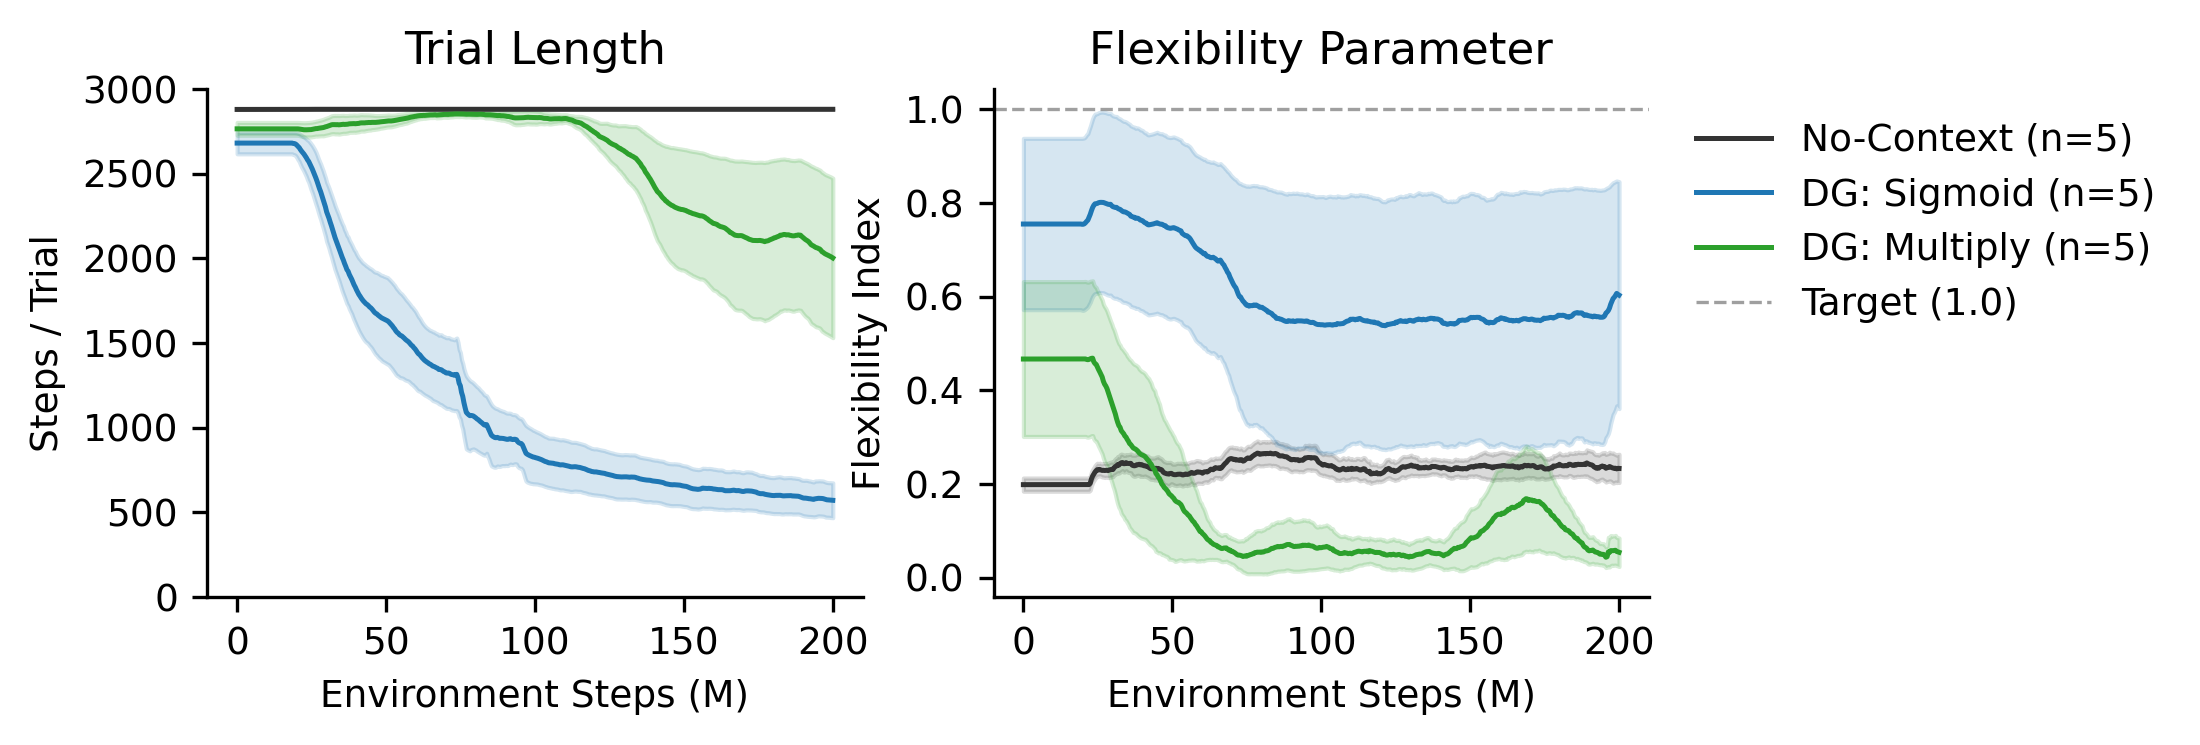

In [181]:
fig, axes = plt.subplots(1, 2, figsize=(6.2, 2.2), dpi=300)

step_axis_millions = target_steps / 1e6
active_setups = [k for k in results if not k.startswith("_")]

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    col = SETUP_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data["n_seeds"]
    label_text = f"{setup_label} (n={n})"

    # --- Panel 1: Trial Length (Mean ± SEM) ---
    axes[0].plot(step_axis_millions, data["tl_avg"], color=col, label=label_text)
    axes[0].fill_between(
        step_axis_millions,
        np.clip(data["tl_avg"] - data["tl_sem"], 0, None),
        data["tl_avg"] + data["tl_sem"],
        color=col, alpha=0.18,
    )

    # --- Panel 2: Flexibility (Mean ± SEM) ---
    axes[1].plot(step_axis_millions, data["flex_avg"], color=col, label=label_text)
    axes[1].fill_between(
        step_axis_millions,
        data["flex_avg"] - data["flex_sem"],
        data["flex_avg"] + data["flex_sem"],
        color=col, alpha=0.18,
    )

# Formatting Panel 1 (Trial Length)
axes[0].set_title("Trial Length", pad=6)
axes[0].set_ylabel("Steps / Trial")
axes[0].set_xlabel("Environment Steps (M)")
axes[0].set_ylim(0, 3000)
style_axes_and_legend(axes[0], legend_loc="upper left", bbox_to_anchor=(1.02, 1))

# Formatting Panel 2 (Flexibility)
axes[1].set_title("Flexibility Parameter", pad=6)
axes[1].set_ylabel("Flexibility Index")
axes[1].set_xlabel("Environment Steps (M)")
axes[1].axhline(1.0, color="#777777", linestyle="--", linewidth=0.8, alpha=0.7, label="Target (1.0)")
axes[1].legend()
style_axes_and_legend(axes[1], legend_loc="upper left", bbox_to_anchor=(1.02, 1))

# Save in vector PDF format and PNG
#plt.savefig("main_result_comparison.pdf", dpi=300)
#plt.savefig("main_result_comparison.png", dpi=300)
plt.show()
#print("Saved publication figures as main_result_comparison.pdf and .png.")


In [218]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ------------------------------------------------------------------------------
# 1. FILE PATHS (handles either "cache_" or "cached_" filename spelling)
# ------------------------------------------------------------------------------
file1_candidates = ["cache_experiments_data.pkl", "cached_experiments_data.pkl"]
file2_candidates = ["cache_experiments_data_cocktail.pkl", "cached_experiments_data_cocktail.pkl"]

file1 = next((f for f in file1_candidates if os.path.exists(f)), file1_candidates[0])
file2 = next((f for f in file2_candidates if os.path.exists(f)), file2_candidates[0])

print(f"Loading Dataset 1 from: {file1}")
with open(file1, "rb") as f:
    data1 = pickle.load(f)

print(f"Loading Dataset 2 (Cocktail) from: {file2}")
with open(file2, "rb") as f:
    data2 = pickle.load(f)

target_steps = data1.get("_target_steps", data2.get("_target_steps"))
step_axis_millions = target_steps / 1e6

# ------------------------------------------------------------------------------
# 2. SELECT & RENAME CONDITIONS FOR PLOTTING
# ------------------------------------------------------------------------------
# Dictionary to store the merged conditions in desired plotting order
plot_data = {}

# --- From File 2: No-Context (Baseline) ---
no_context_key = "No-Context" if "No-Context" in data2 else ("No-contect" if "No-contect" in data2 else None)
if no_context_key and no_context_key in data2:
    plot_data["No-Context"] = data2[no_context_key]
elif "No-Context" in data1:
    plot_data["No-Context"] = data1["No-Context"]

# --- From File 1: Pure DG Modulations ---
for k in ["DG: Sigmoid", "DG: Concat", "DG: Multiply"]:
    if k in data1:
        plot_data[k] = data1[k]
    else:
        print(f"[Warning] '{k}' not found in {file1}")

# --- From File 2: Cocktail Runs (Renamed) ---
if "DG: Sigmoid" in data2:
    plot_data["Decoder + DG: Concat+Sigmoid"] = data2["DG: Sigmoid"]
else:
    print(f"[Warning] 'DG: Sigmoid' not found in {file2}")

print("\nFinal conditions ready to plot:")
for label in plot_data:
    n = plot_data[label].get("n_seeds", len(plot_data[label].get("seeds_tl", [])))
    print(f"  - {label} (n={n})")

Loading Dataset 1 from: cached_experiments_data.pkl
Loading Dataset 2 (Cocktail) from: cached_experiments_data_cocktail.pkl
[Warning] 'DG: Multiply' not found in cached_experiments_data.pkl

Final conditions ready to plot:
  - No-Context (n=5)
  - DG: Sigmoid (n=5)
  - DG: Concat (n=5)
  - Decoder + DG: Concat+Sigmoid (n=5)


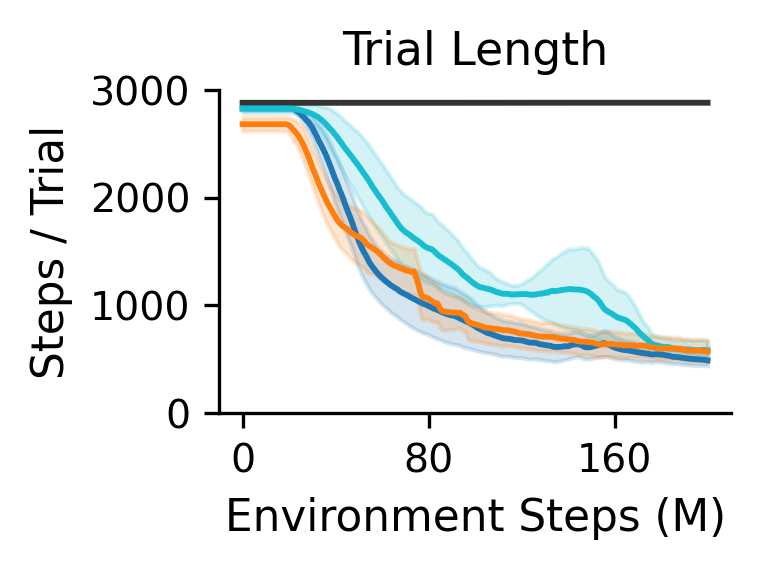

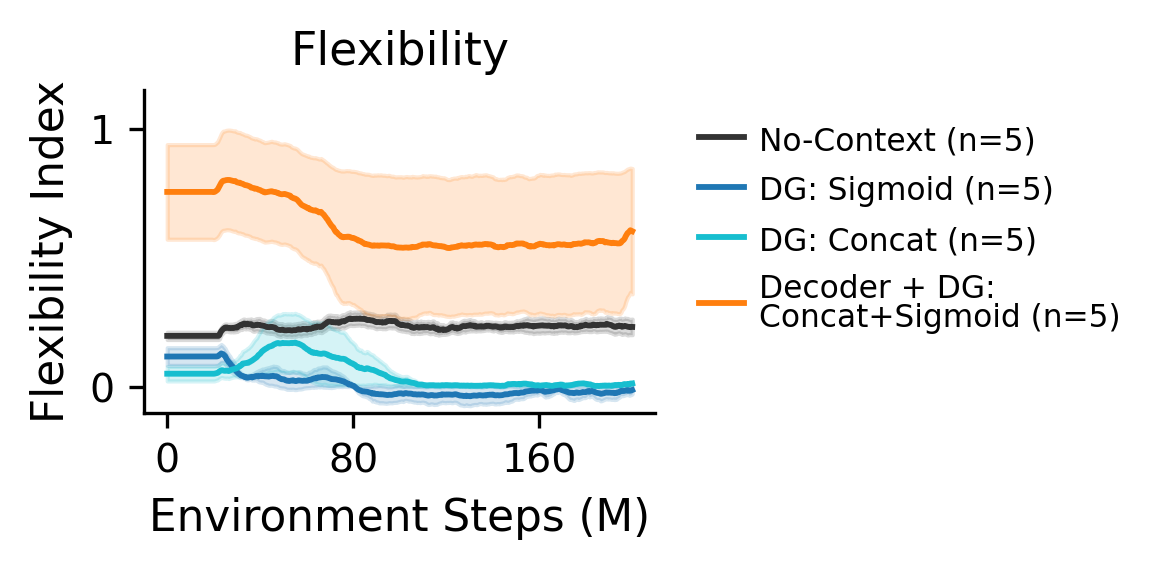

In [219]:
# PLOT 1: TRIAL LENGTH (SEPARATE FIGURE)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(2.2, 1.4), dpi=300)
for label, data in plot_data.items():
    col = CONDITION_COLORS.get(label, "#7f7f7f")
    n = data.get("n_seeds", len(data.get("seeds_tl", [])))
    label_text = format_compact_label(label, n)
    if data.get("tl_avg") is not None and data.get("tl_sem") is not None:
        ax1.plot(step_axis_millions, data["tl_avg"], color=col, label=label_text)
        ax1.fill_between(
            step_axis_millions,
            np.clip(data["tl_avg"] - data["tl_sem"], 0, None),
            data["tl_avg"] + data["tl_sem"],
            color=col,
            alpha=0.18,
        )
ax1.set_title("Trial Length", fontsize=11, pad=6)
ax1.set_ylabel("Steps / Trial", fontsize=10.5)
ax1.set_xlabel("Environment Steps (M)", fontsize=10.5)
ax1.set_ylim(0, 3000)
# Fewer ticks: only [0, 1000, 2000, 3000] on Y, max 3 ticks on X
ax1.set_yticks([0, 1000, 2000, 3000])
ax1.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax1.tick_params(axis='both', labelsize=9.5)
#ax1.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax1)
plt.savefig("trial_length_clean.pdf", dpi=300)
plt.savefig("trial_length_clean.png", dpi=300)
plt.show()
# ==============================================================================
# PLOT 2: FLEXIBILITY (SEPARATE FIGURE)
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(2.2, 1.4), dpi=300)
for label, data in plot_data.items():
    col = CONDITION_COLORS.get(label, "#7f7f7f")
    n = data.get("n_seeds", len(data.get("seeds_tl", [])))
    label_text = format_compact_label(label, n)
    if data.get("flex_avg") is not None and data.get("flex_sem") is not None:
        ax2.plot(step_axis_millions, data["flex_avg"], color=col, label=label_text)
        ax2.fill_between(
            step_axis_millions,
            data["flex_avg"] - data["flex_sem"],
            data["flex_avg"] + data["flex_sem"],
            color=col,
            alpha=0.18,
        )
ax2.set_title("Flexibility", fontsize=11, pad=6)
ax2.set_ylabel("Flexibility Index", fontsize=10.5)
ax2.set_xlabel("Environment Steps (M)", fontsize=10.5)
ax2.set_ylim(-0.1, 1.1)
ax2.set_yticks([0.0, 0.5, 1.15])
# Fewer ticks: max 4 on Y, max 3 on X
ax2.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
ax2.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax2.tick_params(axis='both', labelsize=9.5)
ax2.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax2)
plt.savefig("flexibility_clean_wlegend.pdf", dpi=300)
plt.savefig("flexibility_clean_wlegend.png", dpi=300)
plt.show()

## 5. Detailed Breakdown: Separate Variance Curves & Seed Traces

Inspect the exact **Variance Across Seeds** trajectories over time in row 2, and individual seed trajectories in row 1.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.0), dpi=300, sharex=True)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    col = SETUP_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data["n_seeds"]
    label_text = f"{setup_label} (n={n})"

    # Row 0: Average of policies with faint individual seed traces
    axes[0, 0].plot(step_axis_millions, data["tl_avg"], color=col, label=label_text)
    axes[0, 1].plot(step_axis_millions, data["flex_avg"], color=col, label=label_text)
    
    # Faint individual seed traces (rasterized=True if large number of points for clean vector PDF)
    for s in range(n):
        axes[0, 0].plot(step_axis_millions, data["seeds_tl"][s], color=col, alpha=0.18, linewidth=0.7, rasterized=True)
        axes[0, 1].plot(step_axis_millions, data["seeds_flex"][s], color=col, alpha=0.18, linewidth=0.7, rasterized=True)

    # Row 1: Direct Variance Across Seeds curves
    axes[1, 0].plot(step_axis_millions, data["tl_var"], color=col, label=f"{setup_label}")
    axes[1, 1].plot(step_axis_millions, data["flex_var"], color=col, label=f"{setup_label}")

# Subplot titles and labels
axes[0, 0].set_title(f"Trial Length ({step_unit})", pad=4)
axes[0, 0].set_ylabel("Steps / Trial")
axes[0, 0].legend()
style_axes_and_legend(axes[0, 0], bbox_to_anchor=(1.02, 1))

axes[0, 1].set_title("Flexibility", pad=4)
axes[0, 1].set_ylabel("Flexibility Index")
axes[0, 1].legend()
style_axes_and_legend(axes[0, 1], bbox_to_anchor=(1.02, 1))

axes[1, 0].set_title("Trial Length Variance", pad=4)
axes[1, 0].set_ylabel("Variance")
axes[1, 0].set_xlabel("Environment Steps (M)")
axes[1, 0].legend()
style_axes_and_legend(axes[1, 0], bbox_to_anchor=(1.02, 1))

axes[1, 1].set_title("Flexibility Variance", pad=4)
axes[1, 1].set_ylabel("Variance")
axes[1, 1].set_xlabel("Environment Steps (M)")
axes[1, 1].legend()
style_axes_and_legend(axes[1, 1], bbox_to_anchor=(1.02, 1))

plt.savefig("breakdown_averages_and_variances.pdf", dpi=300)
plt.savefig("breakdown_averages_and_variances.png", dpi=300)
plt.show()
print("Saved breakdown figures as 'breakdown_averages_and_variances.pdf' and '.png'.")
